# 07 — Reverse engineering pola sintetis, RNG, dan jitter

Tujuan notebook ini adalah merekonstruksi aturan observasi dan mengestimasi noise,
bukan menganggap seed generator sudah ditemukan. **Seed RNG asli belum diketahui.**

Kode probe seed, inferensi efek customer, uncertainty, simulasi pendekatan, dan
validasi model terlihat di sel. Data mentah diunduh melalui skrip proyek. Paket:
`requirements-optimization.txt` dan `requirements-notebook.txt`.

Seed untuk simulasi dan pembagian audit dipilih oleh kita; tidak sama dengan seed asli
dataset. Notebook ini tidak mengirim atau mengganti submission.

## 1. Persiapan dan kontrol eksekusi

Audit dapat dijalankan dari data mentah tanpa model versi sebelumnya. Validasi prediksi baru memerlukan fitur dan OOF versi 5; bila belum tersedia, sel menampilkan hasil historis dan menjelaskan prasyaratnya.

In [1]:
from pathlib import Path
import hashlib, itertools, json, os, random, sys, time
import numpy as np
import pandas as pd
from scipy import optimize, special, stats
import matplotlib.pyplot as plt
from IPython.display import display
import joblib
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer, MissingIndicator
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder,
    SplineTransformer,
    PolynomialFeatures,
)
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_curve, roc_auc_score, average_precision_score, log_loss
from threadpoolctl import threadpool_limits

if Path("/tmp/logika-boosting-libs").exists():
    sys.path.insert(0, "/tmp/logika-boosting-libs")
from catboost import CatBoostClassifier

RERUN_RNG_PROBE = True
RECOMPUTE_LATENT_AUDIT = True
RECOMPUTE_MODEL_VALIDATION = True
FORCE_RETRAIN_REVERSE_MODELS = False
RNG_SEED_LIMIT = 10000

ROOT = Path(os.environ.get("LOGIKA_PROJECT_DIR", Path.cwd())).resolve()
if not (ROOT / "scripts/reverse_synthetic_patterns.py").exists():
    ROOT = next(
        p for p in ROOT.parents if (p / "scripts/reverse_synthetic_patterns.py").exists()
    )
RAW = ROOT / "data/raw"
OUT = ROOT / "artifacts/notebook_runs/07_reverse"
OUT.mkdir(parents=True, exist_ok=True)
EXCLUDED = {
    "application_id",
    "customer_id",
    "application_datetime",
    "decision_datetime",
    "target",
    "split",
}
print("NumPy:", np.__version__, "; output:", OUT)

NumPy: 1.24.1 ; output: /home/taqiyudinmiftah/Logika/artifacts/notebook_runs/07_reverse


## 2. EDA: populasi, waktu, dan nominal

Ada satu aplikasi terpilih per customer. ID digunakan untuk join dan diagnosis seed, bukan sebagai fitur numerik. Semua sejarah harus tersedia sebelum keputusan.

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customer_id,100000,100000,C_d2af130dede072b4,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,100000.0,NaN,NaN,NaN,41.50998,10.9672,23.0,32.0,42.0,51.0,60.0
region,100000,5,Region_E,20248,NaN,NaN,NaN,NaN,NaN,NaN,NaN
employment_type,100000,3,salaried,48030,NaN,NaN,NaN,NaN,NaN,NaN,NaN
employment_tenure_months,100000.0,NaN,NaN,NaN,51.60733,33.764842,3.0,26.0,44.0,69.0,297.0
declared_monthly_income,100000.0,NaN,NaN,NaN,9309718.9688,6168829.783689,490493.0,5115223.5,7775115.0,11745819.5,91954431.0
dependents,100000.0,NaN,NaN,NaN,1.64986,1.187702,0.0,1.0,2.0,2.0,4.0
housing_status,100000,3,rented,43032,NaN,NaN,NaN,NaN,NaN,NaN,NaN


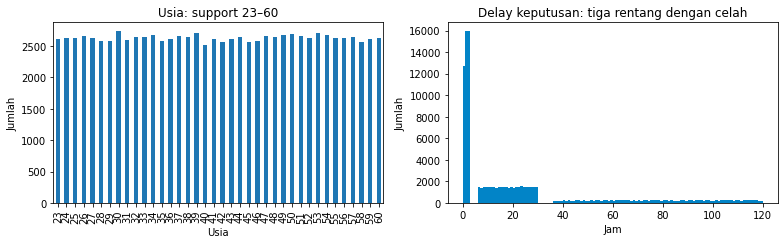

In [2]:
profiles = pd.read_csv(RAW / "customer_profiles.csv")
train_raw = pd.read_csv(
    RAW / "train_applications.csv", parse_dates=["application_datetime", "decision_datetime"]
)
test_raw = pd.read_csv(
    RAW / "test_applications.csv", parse_dates=["application_datetime", "decision_datetime"]
)
train_raw["split"] = "train"
test_raw["split"] = "test"
applications = pd.concat([train_raw, test_raw], ignore_index=True)
base = applications.merge(
    profiles, on="customer_id", how="left", validate="one_to_one", sort=False
).set_index("customer_id")
assert base.index.is_unique and set(train_raw.customer_id).isdisjoint(test_raw.customer_id)
assert applications.decision_datetime.gt(applications.application_datetime).all()
display(profiles.describe(include="all").T)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
profiles.age.value_counts().sort_index().plot.bar(ax=axes[0])
axes[0].set(title="Usia: support 23–60", xlabel="Usia", ylabel="Jumlah")
lag_hours = (
    applications.decision_datetime - applications.application_datetime
).dt.total_seconds() / 3600
axes[1].hist(lag_hours, bins=np.linspace(0, 120, 121), color="#0284c7")
axes[1].set(title="Delay keputusan: tiga rentang dengan celah", xlabel="Jam", ylabel="Jumlah")
plt.tight_layout()
plt.show()

In [3]:
def distribution_summary(values):
    x = np.asarray(values, dtype=float)
    x = x[np.isfinite(x)]
    if len(x) == 0:
        return {"rows": 0}
    sample = np.random.default_rng(91403).choice(x, size=min(50000, len(x)), replace=False)
    mu, sd = stats.norm.fit(sample)
    return {
        "rows": len(x),
        "mean": float(x.mean()),
        "std": float(x.std()),
        "quantiles": dict(
            zip(
                ["q01", "q05", "q50", "q95", "q99"],
                np.quantile(x, [0.01, 0.05, 0.5, 0.95, 0.99]).tolist(),
            )
        ),
        "skewness": float(stats.skew(sample)),
        "excess_kurtosis": float(stats.kurtosis(sample)),
        "normal_fit_ks_descriptive": (
            float(stats.kstest(sample, "norm", args=(mu, sd)).statistic) if sd > 0 else None
        ),
        "normality_caveat": "Descriptive fitted-distribution distance, not a calibrated hypothesis-test p-value.",
    }


def aggregate_ratio_grid(values, steps):
    x = np.asarray(values, dtype=float)
    x = x[np.isfinite(x)]
    return {
        str(step): float(np.isclose(x / step, np.rint(x / step), rtol=0, atol=1e-8).mean())
        for step in steps
    }


def reconstruct_basic_rules(profiles, applications):
    rate = applications.annual_interest_rate.to_numpy() / 12
    amount = applications.loan_amount.to_numpy()
    term = applications.term_months.to_numpy()
    # Stable annuity formula; integer rounding can differ at floating half ties.
    installment = amount * rate / (-np.expm1(-term * np.log1p(rate)))
    observed = applications.proposed_monthly_installment.to_numpy()
    residual = observed - installment
    lag = (
        applications.decision_datetime - applications.application_datetime
    ).dt.total_seconds()
    age_counts = profiles.age.value_counts().sort_index()
    workflow = []
    for low, high in [(0.2, 3), (6, 30), (36, 120)]:
        hours = lag / 3600
        selected = hours[hours.between(low, high)]
        workflow.append(
            {
                "low_hours": low,
                "high_hours": high,
                "observed_fraction": float(len(selected) / len(hours)),
                "rows": len(selected),
                "uniform_fit_ks": float(
                    stats.kstest((selected - low) / (high - low), "uniform").statistic
                ),
            }
        )
    result = {
        "age": {
            "support": [int(profiles.age.min()), int(profiles.age.max())],
            "frequencies": age_counts.to_dict(),
            "uniform_chi2_p": float(stats.chisquare(age_counts).pvalue),
            "interpretation": "Consistent with discrete uniform 23..60. It does not identify the RNG or seed.",
        },
        "profile_categories": {
            c: profiles[c].value_counts(normalize=True).sort_index().to_dict()
            for c in ["dependents", "region", "employment_type", "housing_status"]
        },
        "loan_amount_grid": aggregate_ratio_grid(amount, [1000, 10000, 100000]),
        "annual_interest_rates": applications.annual_interest_rate.value_counts()
        .sort_index()
        .to_dict(),
        "installment": {
            "formula": "P*(r/12)/(1-(1+r/12)^(-term))",
            "nearest_integer_exact_fraction": (
                float(np.rint(installment).eq(observed).mean())
                if isinstance(installment, pd.Series)
                else float((np.rint(installment) == observed).mean())
            ),
            "max_absolute_unrounded_residual_idr": float(np.abs(residual).max()),
            "ceil_exact_fraction": float((np.ceil(installment) == observed).mean()),
            "floor_exact_fraction": float((np.floor(installment) == observed).mean()),
            "signed_residual_idr": distribution_summary(residual),
            "within_one_idr_fraction": float((np.abs(residual) <= 1.000001).mean()),
        },
        "selected_decision_time": {
            "second_zero_fraction": float(
                applications.decision_datetime.dt.second.eq(0).mean()
            ),
            "hour_frequencies": applications.decision_datetime.dt.hour.value_counts()
            .sort_index()
            .to_dict(),
            "application_to_decision_seconds": distribution_summary(lag),
        },
        "workflow_lag_mixture": {
            "components": workflow,
            "candidate_weights": [0.45, 0.35, 0.20],
            "gap_3_6_hours_rows": int((lag / 3600).between(3, 6, inclusive="neither").sum()),
            "gap_30_36_hours_rows": int(
                (lag / 3600).between(30, 36, inclusive="neither").sum()
            ),
            "inference_status": "Intervals are observed support; rounded component probabilities are a generator hypothesis.",
        },
        "inference_status": "Observable quantization and identities are confirmed; generator source code is not available.",
    }
    return result

## 3. Aturan yang dapat direkonstruksi

Rounding berbeda dari noise acak. Bandingkan ceil, floor, dan nearest integer untuk formula anuitas. Probabilitas campuran workflow tetap hipotesis, meski support dan celahnya teramati.

In [4]:
audit = {"basic_rules": reconstruct_basic_rules(profiles, applications)}
display(pd.Series(audit["basic_rules"]["installment"]))
display(pd.DataFrame(audit["basic_rules"]["workflow_lag_mixture"]["components"]))
print("Celah 3–6 jam:", audit["basic_rules"]["workflow_lag_mixture"]["gap_3_6_hours_rows"])
print("Celah 30–36 jam:", audit["basic_rules"]["workflow_lag_mixture"]["gap_30_36_hours_rows"])

formula                                                    P*(r/12)/(1-(1+r/12)^(-term))
nearest_integer_exact_fraction                                                   0.49966
max_absolute_unrounded_residual_idr                                             0.999962
ceil_exact_fraction                                                                  1.0
floor_exact_fraction                                                                 0.0
signed_residual_idr                    {'rows': 100000, 'mean': 0.4996185921258933, '...
within_one_idr_fraction                                                              1.0
dtype: object

,low_hours,high_hours,observed_fraction,rows,uniform_fit_ks
0,0.2,3,0.44624,44624,0.003045
1,6.0,30,0.35268,35268,0.005297
2,36.0,120,0.20108,20108,0.004606


Celah 3–6 jam: 0
Celah 30–36 jam: 0


## 4. Probe RNG yang terbatas dan dapat dibantah

Hipotesis: usia berasal dari stream integer uniform 23..60. Uji pertama memeriksa
PCG64 dan MT19937 pada 10.006 seed, prefix 12 usia, offset dalam 512 draw, dan stride
1–16. Kecocokan prefix wajib diverifikasi pada seluruh 100.000 usia.

Hipotesis tambahan: ID merupakan hash template umum, atau RNG per customer diinisialisasi
dari potongan ID/indeks profil. Memilih offset terbaik menaikkan match rate secara kebetulan;
match beberapa persen bukan penemuan seed. Hasil negatif tidak menyingkirkan urutan
call yang diselingi, row shuffle, library lain, atau seed di luar rentang.

[Dokumentasi NumPy tentang syarat reproduksi stream RNG](https://numpy.org/doc/stable/reference/random/compatibility.html).

In [5]:
def probe_age_sequence(ages, seed_limit=10000):
    """Test uniform integer streams with a small fixed offset/stride hypothesis family."""
    target = np.asarray(ages, dtype=np.int64)
    assert target.min() == 23 and target.max() == 60
    seeds = list(range(seed_limit)) + [
        171327,
        20250101,
        20260101,
        20261010,
        20261013,
        20262026,
    ]
    prefix = target[:12]
    hits = []
    started = time.monotonic()
    for family in ["PCG64", "MT19937_RandomState"]:
        for seed in seeds:
            rng = (
                np.random.Generator(np.random.PCG64(seed))
                if family == "PCG64"
                else np.random.RandomState(seed)
            )
            drawn = (
                rng.integers(23, 61, size=512)
                if family == "PCG64"
                else rng.randint(23, 61, size=512)
            )
            for stride in range(1, 17):
                offsets = np.flatnonzero(
                    (drawn[:-stride] == prefix[0]) & (drawn[stride:] == prefix[1])
                )
                offsets = offsets[offsets + 11 * stride < len(drawn)]
                for offset in offsets:
                    if np.array_equal(drawn[offset + stride * np.arange(12)], prefix):
                        rng = (
                            np.random.Generator(np.random.PCG64(seed))
                            if family == "PCG64"
                            else np.random.RandomState(seed)
                        )
                        length = int(offset + stride * (len(target) - 1) + 1)
                        extended = (
                            rng.integers(23, 61, size=length)
                            if family == "PCG64"
                            else rng.randint(23, 61, size=length)
                        )
                        matched = extended[offset + stride * np.arange(len(target))] == target
                        hits.append(
                            {
                                "family": family,
                                "seed": seed,
                                "offset": int(offset),
                                "stride": stride,
                                "full_rows": len(target),
                                "full_match_fraction": float(matched.mean()),
                                "exact_full_sequence": bool(matched.all()),
                            }
                        )
        print("Completed RNG probe:", family, flush=True)
    return {
        "seed_count_per_family": len(seeds),
        "integer_support": [23, 60],
        "prefix_length": 12,
        "stream_length": 512,
        "strides": [1, 16],
        "families": ["PCG64", "MT19937_RandomState"],
        "hits": hits,
        "elapsed_seconds": time.monotonic() - started,
        "inferred_generator_seed": next(
            (h["seed"] for h in hits if h["exact_full_sequence"]), None
        ),
        "limitations": "Only direct uniform integer streams and fixed offsets/strides. Unknown interleaved calls, shuffled rows, other RNGs and seeds outside the tested set are not ruled out.",
    }

In [6]:
def probe_id_hashes(customer_ids):
    """Check common deterministic ID templates using no targets or model features."""
    observed = [str(s).split("_", 1)[1] for s in customer_ids[:3]]
    hashes = {
        "sha256_first16": lambda b: hashlib.sha256(b).hexdigest()[:16],
        "sha1_first16": lambda b: hashlib.sha1(b).hexdigest()[:16],
        "md5_first16": lambda b: hashlib.md5(b).hexdigest()[:16],
        "blake2b_8": lambda b: hashlib.blake2b(b, digest_size=8).hexdigest(),
    }
    matches, tested = [], 0
    for prefix, separator, start, seed in itertools.product(
        ["C", "c", "customer", "cust", "customer_id", "profile"],
        ["_", ":", "-", "/", ""],
        [0, 1],
        ["", "42", "2025", "2026", "20261010", "LOGIKA2026", "logika2026"],
    ):
        formats = [("prefix_index", lambda i: separator.join([prefix, str(i)]))]
        if seed:
            formats += [
                ("prefix_seed_index", lambda i: separator.join([prefix, seed, str(i)])),
                ("seed_prefix_index", lambda i: separator.join([seed, prefix, str(i)])),
                ("prefix_index_seed", lambda i: separator.join([prefix, str(i), seed])),
            ]
        for name, template in formats:
            for hash_name, hash_fn in hashes.items():
                tested += 1
                generated = [hash_fn(template(i + start).encode()) for i in range(3)]
                if generated == observed:
                    matches.append(
                        {
                            "prefix": prefix,
                            "separator": separator,
                            "index_start": start,
                            "seed_or_salt": seed,
                            "template": name,
                            "hash": hash_name,
                        }
                    )
    return {
        "templates_tested": tested,
        "confirmed_three_row_matches": matches,
        "id_model_features_used": False,
        "limitations": "Truncated hexadecimal IDs alone do not reveal an RNG or seed. Template search is intentionally bounded.",
    }

In [7]:
def probe_per_customer_rng(customer_ids, ages):
    ids = np.array(
        [int(str(s).split("_", 1)[1], 16) for s in customer_ids[:1000]], dtype=np.uint64
    )
    observed = np.asarray(ages[:1000])
    results = []
    for family in ["PCG64", "MT19937_RandomState"]:
        methods = {
            "id_low32": ids % 2**32,
            "id_high32": ids // 2**32,
            "profile_index_zero": np.arange(len(ids)),
            "profile_index_one": np.arange(len(ids)) + 1,
        }
        if family == "PCG64":
            methods["id_uint64"] = ids
        for method, seeds in methods.items():
            draws = []
            for seed in seeds:
                if family == "PCG64":
                    draws.append(
                        np.random.Generator(np.random.PCG64(int(seed))).integers(
                            23, 61, size=128
                        )
                    )
                else:
                    draws.append(np.random.RandomState(int(seed)).randint(23, 61, size=128))
            rates = (np.vstack(draws) == observed[:, None]).mean(axis=0)
            best = int(np.argmax(rates))
            results.append(
                {
                    "family": family,
                    "seed_mapping": method,
                    "best_offset": best,
                    "age_match_fraction_at_best_offset": float(rates[best]),
                    "all_rows_match": bool(rates[best] == 1),
                }
            )
    return {
        "customers": len(ids),
        "offsets": [0, 127],
        "results": results,
        "null_single_offset_expected_match_fraction": 1 / 38,
        "max_offset_selection_inflates_null_match_rate": True,
        "id_values_used_only_for_diagnostic_seed_hypotheses": True,
    }

In [8]:
def probe_raw_identifier_stream(customer_ids, seed_limit=10000):
    """Test whether hex IDs are unmodified 64-bit outputs or 8 random bytes."""
    hexadecimal = [str(s).split("_", 1)[1] for s in customer_ids[:3]]
    targets = {
        "hex_integer_big_endian": np.array([int(s, 16) for s in hexadecimal], dtype=np.uint64),
        "bytes_little_endian": np.array(
            [int.from_bytes(bytes.fromhex(s), "little") for s in hexadecimal],
            dtype=np.uint64,
        ),
    }

    def draws(family, seed, n):
        if family in ["PCG64", "PCG64DXSM", "Philox", "SFC64"]:
            return getattr(np.random, family)(seed).random_raw(n)
        if family == "NumPy_RandomState_uint64":
            return np.random.RandomState(seed).randint(
                0, np.iinfo(np.uint64).max, size=n, dtype=np.uint64
            )
        if family == "NumPy_RandomState_bytes":
            return np.frombuffer(np.random.RandomState(seed).bytes(n * 8), dtype="<u8")
        rng = random.Random(seed)
        return np.fromiter((rng.getrandbits(64) for _ in range(n)), dtype=np.uint64, count=n)

    families = [
        "PCG64",
        "PCG64DXSM",
        "NumPy_RandomState_uint64",
        "NumPy_RandomState_bytes",
        "Python_random_getrandbits64",
    ]
    seeds = list(range(seed_limit)) + [
        171327,
        20250101,
        20260101,
        20261010,
        20261013,
        20262026,
    ]
    candidates = []

    def inspect(family, seed, n):
        values = draws(family, seed, n)
        for encoding, target in targets.items():
            positions = np.flatnonzero(values == target[0])
            for position in positions:
                extended = values if n == 1000000 else draws(family, seed, 1000000)
                match_positions = [int(position)]
                for next_target in target[1:]:
                    matches = np.flatnonzero(extended == next_target)
                    matches = matches[matches > match_positions[-1]]
                    if not len(matches):
                        break
                    match_positions.append(int(matches[0]))
                candidates.append(
                    {
                        "family": family,
                        "seed": seed,
                        "encoding": encoding,
                        "raw_positions": match_positions,
                        "three_ordered_ids_reproduced": len(match_positions) == 3,
                    }
                )

    for family in families:
        for seed in seeds:
            inspect(family, seed, 512)
        print("Completed raw ID output probe:", family, flush=True)
    long_seeds = [
        0,
        1,
        7,
        17,
        42,
        123,
        1234,
        2025,
        2026,
        20261010,
        20260101,
        20261013,
        171327,
        9173,
        8247,
    ]
    for family in families + ["Philox", "SFC64"]:
        for seed in long_seeds:
            inspect(family, seed, 1000000)
    return {
        "families_prefix_probe": families,
        "seed_count_per_family": len(seeds),
        "prefix_raw_outputs": 512,
        "extra_long_stream_families": families + ["Philox", "SFC64"],
        "extra_long_stream_seeds": long_seeds,
        "long_stream_length": 1000000,
        "first_id_exact_matches": candidates,
        "any_three_ordered_id_match": any(
            r["three_ordered_ids_reproduced"] for r in candidates
        ),
        "limitations": "Only IDs formed directly from integer outputs or raw bytes. Hashes, UUIDs, separate cryptographic RNGs, other seeds and later call states are not ruled out.",
    }

In [9]:
def untemper_mt_word(value):
    """Undo the four MT19937 output-tempering operations on one 32-bit word."""

    def undo_right(y, shift):
        x = y
        for _ in range(32 // shift + 1):
            x = y ^ (x >> shift)
        return x & 0xFFFFFFFF

    def undo_left(y, shift, mask):
        x = y
        for _ in range(32 // shift + 1):
            x = y ^ ((x << shift) & mask)
        return x & 0xFFFFFFFF

    x = undo_right(int(value), 18)
    x = undo_left(x, 15, 0xEFC60000)
    x = undo_left(x, 7, 0x9D2C5680)
    return undo_right(x, 11)

In [10]:
def predict_mt_after_observed_words(words):
    assert len(words) > 624
    cloned = random.Random(0)
    cloned.setstate((3, tuple(untemper_mt_word(w) for w in words[:624]) + (624,), None))
    return [cloned.getrandbits(32) for _ in words[624:]]

In [11]:
def probe_mt_state_clone(customer_ids):
    """A seed-free falsification of consecutive raw-MT words encoded as 64-bit IDs."""
    control = random.Random(81721)
    for _ in range(37):
        control.getrandbits(32)
    control_words = [control.getrandbits(32) for _ in range(1200)]
    assert predict_mt_after_observed_words(control_words) == control_words[624:]
    numpy_words = (
        np.random.RandomState(231).randint(0, 2**32, size=1200, dtype=np.uint32).tolist()
    )
    assert predict_mt_after_observed_words(numpy_words) == numpy_words[624:]
    hexadecimal = [str(s).split("_", 1)[1] for s in customer_ids[:1000]]
    results = []
    for encoding in ["big", "little"]:
        ids = [int.from_bytes(bytes.fromhex(s), encoding) for s in hexadecimal]
        for word_order in ["low_high", "high_low"]:
            words = []
            for number in ids:
                pair = [number & 0xFFFFFFFF, number >> 32]
                words.extend(pair if word_order == "low_high" else pair[::-1])
            predicted = predict_mt_after_observed_words(words)
            observed = words[624:]
            matches = np.array(predicted, dtype=np.uint32) == np.array(
                observed, dtype=np.uint32
            )
            results.append(
                {
                    "encoding": encoding,
                    "word_order": word_order,
                    "fitting_words": 624,
                    "independent_test_words": len(observed),
                    "matching_words": int(matches.sum()),
                    "all_test_words_match": bool(matches.all()),
                }
            )
    return {
        "python_positive_control_passed": True,
        "numpy_positive_control_passed": True,
        "results": results,
        "any_consecutive_mt_stream_detected": any(r["all_test_words_match"] for r in results),
        "limitations": "Requires consecutive unmodified 32-bit MT outputs. Hashing, interleaved calls, row permutation or another RNG defeats this particular test.",
    }

In [12]:
if RERUN_RNG_PROBE:
    rng_report = {
        "numpy_version": np.__version__,
        "age_stream": probe_age_sequence(profiles.age.to_numpy(), RNG_SEED_LIMIT),
        "id_templates": probe_id_hashes(profiles.customer_id.to_numpy()),
        "per_customer_seed_probe": probe_per_customer_rng(
            profiles.customer_id.to_numpy(), profiles.age.to_numpy()
        ),
    }
    rng_report["raw_identifier_stream_probe"] = probe_raw_identifier_stream(
        profiles.customer_id.to_numpy(), RNG_SEED_LIMIT
    )
    rng_report["mt_state_clone_probe"] = probe_mt_state_clone(profiles.customer_id.to_numpy())
    rng_report["original_generator_seed_recovered"] = any(
        h["exact_full_sequence"] for h in rng_report["age_stream"]["hits"]
    )
else:
    rng_report = json.loads(
        (ROOT / "artifacts/reverse_engineering/rng_probe.json").read_text()
    )
(OUT / "rng_probe.json").write_text(json.dumps(rng_report, indent=2))
print("Seed asli ditemukan:", rng_report["original_generator_seed_recovered"])
display(pd.DataFrame(rng_report["per_customer_seed_probe"]["results"]))
print("Kecocokan stream umur:", rng_report["age_stream"]["hits"])
print("Kecocokan hash ID:", rng_report["id_templates"]["confirmed_three_row_matches"])
print(
    "Kecocokan ID sebagai raw RNG:",
    rng_report["raw_identifier_stream_probe"]["first_id_exact_matches"],
)
display(pd.DataFrame(rng_report["mt_state_clone_probe"]["results"]))
print(
    "Positive control cloning MT berhasil:",
    rng_report["mt_state_clone_probe"]["python_positive_control_passed"],
    rng_report["mt_state_clone_probe"]["numpy_positive_control_passed"],
)

Completed RNG probe: PCG64


Completed RNG probe: MT19937_RandomState


Completed raw ID output probe: PCG64


Completed raw ID output probe: PCG64DXSM


Completed raw ID output probe: NumPy_RandomState_uint64


...

Seed asli ditemukan: False


,family,seed_mapping,best_offset,age_match_fraction_at_best_offset,all_rows_match
0,PCG64,id_low32,27,0.038,False
1,PCG64,id_high32,113,0.043,False
2,PCG64,profile_index_zero,59,0.038,False
3,PCG64,profile_index_one,31,0.040,False
4,PCG64,id_uint64,117,0.040,False
5,MT19937_RandomState,id_low32,10,0.041,False
6,MT19937_RandomState,id_high32,82,0.045,False
7,MT19937_RandomState,profile_index_zero,12,0.038,False
8,MT19937_RandomState,profile_index_one,127,0.041,False


Kecocokan stream umur: []
Kecocokan hash ID: []
Kecocokan ID sebagai raw RNG: []


,encoding,word_order,fitting_words,independent_test_words,matching_words,all_test_words_match
0,big,low_high,624,1376,0,False
1,big,high_low,624,1376,0,False
2,little,low_high,624,1376,0,False
3,little,high_low,624,1376,0,False


Positive control cloning MT berhasil: True True


## 5. Memisahkan preferensi harga dan noise item

Model pendekatan: `log(unit_price) = efek kategori + efek customer + efek order + noise item`.
Selisih dua item dalam order yang sama membatalkan customer/order. Varians efek order
dipisahkan dari noise item dengan koreksi ukuran basket. Precision weighting dan empirical
Bayes mengestimasi preferensi customer beserta standard error.

Semua basket boleh mengungkapkan pilihan harga, termasuk cancelled; nilai cancelled
tidak dihitung sebagai spending. Parameter dipelajari dari sejarah customer train tanpa target.
Intercept kategori dan efek customer memiliki origin bersama yang tidak teridentifikasi;
mean efek customer nol hanya konvensi. Estimasi bukan nilai laten asli yang diketahui.

In [13]:
def fit_price_latent(base):
    columns = [
        "customer_id",
        "order_id",
        "product_category",
        "quantity",
        "item_total",
        "transaction_datetime",
    ]
    events = pd.read_csv(
        ROOT / "data/raw/ecommerce_transactions.csv",
        usecols=columns,
        parse_dates=["transaction_datetime"],
        dtype={"customer_id": "category", "product_category": "category"},
    )
    cutoffs = base.decision_datetime
    assert events.transaction_datetime.lt(
        events.customer_id.map(cutoffs).astype("datetime64[ns]")
    ).all()
    assert events.quantity.gt(0).all()
    ids = pd.Series(np.arange(len(base)), index=base.index)
    customer = events.customer_id.map(ids).to_numpy(dtype=np.int64)
    category, categories = pd.factorize(events.product_category, sort=True)
    order, orders = pd.factorize(events.order_id, sort=False)
    first = ~events.order_id.duplicated().to_numpy()
    order_customer = customer[first]
    quantity = events.quantity.to_numpy()
    unit = events.item_total.to_numpy() / quantity
    log_price = np.log(unit)
    n_customer = np.bincount(customer, minlength=len(base))
    n_order = np.bincount(order)
    train_customer = base.split.eq("train").to_numpy()
    training = train_customer[customer]
    n_category = np.bincount(category[training], minlength=len(categories))
    intercept = np.bincount(category[training], weights=log_price[training]) / n_category
    # Two-way fixed effects remove product composition while fitting a customer preference.
    for _ in range(8):
        customer_effect = (
            np.bincount(customer, weights=log_price - intercept[category], minlength=len(base))
            / n_customer
        )
        intercept = (
            np.bincount(
                category[training],
                weights=(log_price - customer_effect[customer])[training],
            )
            / n_category
        )
        center = float(customer_effect[train_customer].mean())
        customer_effect -= center
        intercept += center
    adjusted = log_price - intercept[category]
    order_mean = np.bincount(order, weights=adjusted) / n_order
    train_order = train_customer[order_customer]
    item_df = int((n_order[train_order] - 1).sum())
    item_noise_variance = float(
        np.square((adjusted - order_mean[order])[training]).sum() / item_df
    )
    orders_per_customer = np.bincount(order_customer, minlength=len(base))
    equal_order_mean = (
        np.bincount(order_customer, weights=order_mean, minlength=len(base))
        / orders_per_customer
    )
    order_df = int((orders_per_customer[train_customer] - 1).sum())
    centered_order_ss = float(
        np.square(order_mean - equal_order_mean[order_customer])[train_order].sum()
    )
    correction = item_noise_variance * float(
        ((1 - 1 / orders_per_customer[order_customer]) / n_order)[train_order].sum()
    )
    order_noise_variance = max((centered_order_ss - correction) / order_df, 0)
    observation_variance = order_noise_variance + item_noise_variance / n_order
    weight = 1 / np.maximum(observation_variance, 1e-12)
    precision = np.bincount(order_customer, weights=weight, minlength=len(base))
    raw_effect = (
        np.bincount(order_customer, weights=weight * order_mean, minlength=len(base))
        / precision
    )
    prior_mean = float(raw_effect[train_customer].mean())
    prior_variance = max(
        float(raw_effect[train_customer].var() - np.mean(1 / precision[train_customer])),
        1e-8,
    )
    posterior_variance = 1 / (precision + 1 / prior_variance)
    posterior_mean = posterior_variance * (
        precision * raw_effect + prior_mean / prior_variance
    )
    features = pd.DataFrame(
        {
            "re_price_log_gls": raw_effect,
            "re_price_log_posterior": posterior_mean,
            "re_price_posterior_sd": np.sqrt(posterior_variance),
            "re_price_measurement_sd": np.sqrt(1 / precision),
            "re_price_latent_multiplier": np.exp(posterior_mean),
            "re_price_order_noise_sd": np.sqrt(order_noise_variance),
        },
        index=base.index,
    )
    same_previous_order = np.r_[False, order[1:] == order[:-1]]
    paired = np.diff(adjusted)[same_previous_order[1:]]
    residual = adjusted - customer_effect[customer]
    category_jitter = {}
    for j, name in enumerate(categories):
        category_jitter[str(name)] = distribution_summary(residual[training & (category == j)])
    # A separate order split tests repeatability of the estimated preference, without targets.
    second_half = np.random.default_rng(18117).integers(0, 2, size=len(n_order)).astype(bool)
    half_estimates = []
    for half in [second_half, ~second_half]:
        part_weight = weight * half
        p = np.bincount(order_customer, weights=part_weight, minlength=len(base))
        half_estimates.append(
            np.bincount(order_customer, weights=part_weight * order_mean, minlength=len(base))
            / np.where(p > 0, p, np.nan)
        )
    eligible = train_customer & np.isfinite(half_estimates[0]) & np.isfinite(half_estimates[1])
    audit = {
        "rows": len(events),
        "orders": len(n_order),
        "future_rows": 0,
        "targets_used": False,
        "unit_price_grid": aggregate_ratio_grid(unit, [100, 500, 1000]),
        "minimum_unit_price_idr": float(unit.min()),
        "unit_price_at_5000_fraction": float((unit == 5000).mean()),
        "unit_rounded_before_quantity_exact_fraction": float(
            events.item_total.mod(events.quantity * 1000).eq(0).mean()
        ),
        "category_log_intercepts": dict(zip(map(str, categories), intercept.tolist())),
        "category_geometric_baselines_idr": dict(
            zip(map(str, categories), np.exp(intercept).tolist())
        ),
        "estimated_item_log_noise_sd": float(np.sqrt(item_noise_variance)),
        "estimated_shared_order_log_noise_sd": float(np.sqrt(order_noise_variance)),
        "estimated_customer_effect_prior_sd": float(np.sqrt(prior_variance)),
        "within_order_pair_difference": distribution_summary(paired),
        "category_residuals": category_jitter,
        "order_split_customer_effect_correlation": float(
            np.corrcoef(half_estimates[0][eligible], half_estimates[1][eligible])[0, 1]
        ),
        "latent_customer_effect": distribution_summary(raw_effect[train_customer]),
        "quantization_interval_idr": "For unit prices above floor: pre-rounded unit value approximately in [unit-500,unit+500); item_total = rounded_unit*quantity.",
        "location_identifiability": "Category intercepts and customer effects have a shared arbitrary additive origin. Centering the mean training customer effect at zero fixes a convention, not the original generator scale.",
        "inference_status": "Variance components and latent values are estimates under an additive log-price random-effects model, not recovered original RNG draws.",
    }
    print("Ecommerce latent/noise analysis complete.", flush=True)
    return (
        features,
        audit,
        {
            "item_pair_difference": paired[:: max(1, len(paired) // 50000)],
            "latent_price": raw_effect[train_customer],
            "price_residual": residual[training][::100],
        },
    )

## 6. Jitter biro, income, dan pembayaran

Biro: pasangan provider pada aplikasi yang sama mengurangi variasi kemampuan customer.
Asumsi independensi memberi `Var(A-B)=Var(error_A)+Var(error_B)`. Income memakai
selisih log antarbulan; tail/shock/tren dapat mencampur noise efektif. Pembayaran memakai
prior beta-binomial dari frekuensi historis, dengan maturity filter untuk ambang DPD.
Dependensi cicilan bisa membuat uncertainty terlalu optimistis. Label default tidak dipakai.

In [14]:
def fit_bureau_latent(base):
    bureau = pd.read_csv(
        ROOT / "data/raw/bureau_observations.csv",
        parse_dates=["report_datetime", "available_datetime"],
    )
    bureau = bureau.merge(
        base[["decision_datetime"]],
        left_on="customer_id",
        right_index=True,
        validate="many_to_one",
    )
    assert (
        bureau.report_datetime.lt(bureau.decision_datetime).all()
        and bureau.available_datetime.lt(bureau.decision_datetime).all()
    )
    training_ids = base.index[base.split.eq("train")]
    paired = bureau.pivot_table(
        index=["customer_id", "application_id"],
        columns="bureau_provider",
        values="score",
        aggfunc="mean",
    )
    paired_train = paired[paired.index.get_level_values("customer_id").isin(training_ids)]
    names = sorted(paired.columns)
    differences, variances, mean_differences = {}, {}, {}
    for a, b in [(names[0], names[1]), (names[0], names[2]), (names[1], names[2])]:
        values = (paired_train[a] - paired_train[b]).dropna().to_numpy()
        differences[a + "-" + b] = distribution_summary(values)
        variances[(a, b)] = float(values.var())
        mean_differences[(a, b)] = float(values.mean())
    # Solve differences with the first provider as reference; then center the offsets.
    offsets = np.array(
        [
            0,
            -mean_differences[(names[0], names[1])],
            -mean_differences[(names[0], names[2])],
        ]
    )
    offsets -= offsets.mean()
    v01, v02, v12 = [
        variances[p]
        for p in [(names[0], names[1]), (names[0], names[2]), (names[1], names[2])]
    ]
    noise = np.maximum(
        np.array([(v01 + v02 - v12) / 2, (v01 + v12 - v02) / 2, (v02 + v12 - v01) / 2]),
        1e-8,
    )
    offset_map, variance_map = dict(zip(names, offsets)), dict(zip(names, noise))
    bureau["adjusted_score"] = bureau.score - bureau.bureau_provider.map(offset_map)
    bureau["precision"] = 1 / bureau.bureau_provider.map(variance_map)
    bureau["precision"] = bureau.precision.where(bureau.score.notna(), 0)
    bureau["weighted_score"] = bureau.adjusted_score.fillna(0) * bureau.precision
    summary = (
        bureau.groupby("customer_id")[["precision", "weighted_score"]]
        .sum()
        .reindex(base.index)
    )
    mean = summary.weighted_score / summary.precision.where(summary.precision.gt(0))
    train_mean = mean.reindex(training_ids).dropna()
    mean_precision = summary.precision.reindex(train_mean.index)
    prior_mean = float(train_mean.mean())
    prior_variance = max(float(train_mean.var(ddof=0) - (1 / mean_precision).mean()), 1e-8)
    posterior_variance = 1 / (summary.precision.fillna(0) + 1 / prior_variance)
    posterior_mean = posterior_variance * (
        summary.weighted_score.fillna(0) + prior_mean / prior_variance
    )
    features = pd.DataFrame(
        {
            "re_bureau_score_gls": mean,
            "re_bureau_score_posterior": posterior_mean,
            "re_bureau_posterior_sd": np.sqrt(posterior_variance),
        },
        index=base.index,
    )
    availability_days = (
        bureau.available_datetime - bureau.report_datetime
    ).dt.total_seconds() / 86400
    audit = {
        "rows": len(bureau),
        "targets_used": False,
        "future_report_rows": 0,
        "future_available_rows": 0,
        "score_integer_fraction": float(bureau.score.dropna().mod(1).eq(0).mean()),
        "report_second_zero_fraction": float(bureau.report_datetime.dt.second.eq(0).mean()),
        "availability_lag_days": distribution_summary(availability_days),
        "estimated_provider_offsets": dict(zip(names, offsets.tolist())),
        "estimated_provider_noise_sd": dict(zip(names, np.sqrt(noise).tolist())),
        "estimated_latent_score_prior_mean": prior_mean,
        "estimated_latent_score_prior_sd": float(np.sqrt(prior_variance)),
        "pair_differences": differences,
        "inference_status": "Same-application paired scores estimate offset/noise under independent unbiased provider errors. Age effects, dependence and clipping can violate that model.",
    }
    print("Bureau matched-pair noise analysis complete.", flush=True)
    return (
        features,
        audit,
        (paired_train[names[0]] - paired_train[names[1]]).dropna().to_numpy()[::5],
    )

In [15]:
def fit_account_latent(base):
    account = pd.read_csv(ROOT / "data/raw/account_behavior.csv", parse_dates=["month"])
    account = account.merge(
        base[["decision_datetime", "employment_type"]],
        left_on="customer_id",
        right_index=True,
        validate="many_to_one",
    )
    assert (account.month + pd.offsets.MonthBegin(1)).le(account.decision_datetime).all()
    account.sort_values(["customer_id", "month"], inplace=True)
    previous = account.groupby("customer_id").closing_balance.shift()
    carry = (account.opening_balance - previous).dropna()
    balance_residual = (
        account.closing_balance - account.opening_balance - account.inflows + account.outflows
    )
    account["log_income"] = np.log(
        account.income_like_credits.where(account.income_like_credits.gt(0))
    )
    account["log_outflow"] = np.log(account.outflows.where(account.outflows.gt(0)))
    summary = (
        account.groupby("customer_id")
        .agg(
            log_income=("log_income", "mean"),
            log_income_std=("log_income", "std"),
            log_outflow=("log_outflow", "mean"),
            n=("log_income", "count"),
        )
        .reindex(base.index)
    )
    account["income_log_difference"] = account.groupby("customer_id").log_income.diff()
    jitter = {
        str(name): distribution_summary(part.income_log_difference.dropna())
        for name, part in account.groupby("employment_type")
    }
    variance_map = {
        str(name): float(part.income_log_difference.dropna().var(ddof=0) / 2)
        for name, part in account.groupby("employment_type")
    }
    measurement_variance = base.employment_type.map(variance_map) / summary.n.where(
        summary.n.gt(0)
    )
    features = pd.DataFrame(
        {
            "re_income_geometric_mean": np.exp(summary.log_income),
            "re_income_log_mean": summary.log_income,
            "re_income_log_sd": summary.log_income_std,
            "re_income_log_measurement_sd": np.sqrt(measurement_variance),
            "re_declared_income_log_gap": np.log(base.declared_monthly_income)
            - summary.log_income,
            "re_outflow_income_geometric_ratio": np.exp(
                summary.log_outflow - summary.log_income
            ),
        },
        index=base.index,
    )
    average_residual = (
        account.average_balance - (account.opening_balance + account.closing_balance) / 2
    )
    normalized = average_residual / account.income_like_credits.where(
        account.income_like_credits.gt(0)
    )
    audit = {
        "rows": len(account),
        "targets_used": False,
        "incomplete_month_rows": 0,
        "opening_matches_previous_closing_fraction": float(carry.eq(0).mean()),
        "balance_identity_exact_fraction": float(balance_residual.eq(0).mean()),
        "income_adjacent_log_difference_by_employment": jitter,
        "estimated_iid_log_income_noise_sd_by_employment": {
            k: float(np.sqrt(v)) for k, v in variance_map.items()
        },
        "average_balance_midpoint_residual_in_income_units": distribution_summary(normalized),
        "inference_status": "Income jitter estimate uses Var(log income_t-log income_(t-1))/2. Trend, autocorrelation and shocks can invalidate the iid assumption.",
    }
    print("Account identities and income jitter analysis complete.", flush=True)
    return features, audit, account.income_log_difference.dropna().to_numpy()[::20]

In [16]:
def beta_binomial_prior(k, n):
    k, n = np.asarray(k, dtype=float), np.asarray(n, dtype=float)
    positive = n > 0
    k, n = k[positive], n[positive]
    initial_mean = np.clip(k.sum() / n.sum(), 1e-5, 1 - 1e-5)

    def objective(log_params):
        alpha, beta = np.exp(log_params)
        return float(
            -(special.betaln(k + alpha, n - k + beta) - special.betaln(alpha, beta)).sum()
        )

    result = optimize.minimize(
        objective,
        np.log([initial_mean * 12, (1 - initial_mean) * 12]),
        method="L-BFGS-B",
        bounds=[(-7, 10), (-7, 10)],
    )
    assert result.success, result.message
    alpha, beta = np.exp(result.x)
    return {
        "alpha": float(alpha),
        "beta": float(beta),
        "strength": float(alpha + beta),
        "mean": float(alpha / (alpha + beta)),
        "customers": len(n),
        "optimizer_success": bool(result.success),
    }

In [17]:
def fit_repayment_latent(base):
    repayment = pd.read_csv(
        ROOT / "data/raw/repayment_history.csv",
        parse_dates=["due_date", "last_payment_datetime"],
    )
    repayment = repayment.merge(
        base[["decision_datetime"]],
        left_on="customer_id",
        right_index=True,
        validate="many_to_one",
    )
    assert repayment.due_date.lt(repayment.decision_datetime).all()
    assert (
        repayment.last_payment_datetime.isna()
        | repayment.last_payment_datetime.lt(repayment.decision_datetime)
    ).all()
    repayment["age"] = (
        repayment.decision_datetime - repayment.due_date
    ).dt.total_seconds() / 86400
    features = pd.DataFrame(index=base.index)
    audit = {
        "rows": len(repayment),
        "targets_used": False,
        "future_due_rows": 0,
        "future_payment_rows": 0,
        "beta_binomial_priors": {},
    }
    train_ids = base.index[base.split.eq("train")]
    for threshold in [1, 7, 30]:
        eligible = repayment[repayment.age.ge(threshold)].copy()
        eligible["late"] = eligible.max_days_past_due.ge(threshold).astype(int)
        counts = (
            eligible.groupby("customer_id")
            .late.agg(["sum", "count"])
            .reindex(base.index)
            .fillna(0)
        )
        prior = beta_binomial_prior(
            counts["sum"].reindex(train_ids), counts["count"].reindex(train_ids)
        )
        a, b = prior["alpha"], prior["beta"]
        denominator = counts["count"] + a + b
        features[f"re_late_{threshold}_posterior"] = (counts["sum"] + a) / denominator
        features[f"re_late_{threshold}_posterior_sd"] = np.sqrt(
            (counts["sum"] + a)
            * (counts["count"] - counts["sum"] + b)
            / (denominator**2 * (denominator + 1))
        )
        audit["beta_binomial_priors"][str(threshold)] = prior
    paid_fraction = repayment.amount_paid / repayment.amount_due
    audit["payment_fraction"] = distribution_summary(paid_fraction)
    audit["full_payment_fraction"] = float(paid_fraction.eq(1).mean())
    audit["current_dpd_frequencies_top20"] = (
        repayment.days_past_due.value_counts().head(20).to_dict()
    )
    audit["inference_status"] = (
        "Historical propensity posterior, not original Bernoulli RNG recovery. Payment dependence/censoring may overstate precision."
    )
    print("Repayment empirical-Bayes propensity analysis complete.", flush=True)
    return features, audit

## 7. Jalankan inferensi pada data mentah

Hasil per customer disimpan di folder runtime notebook. Bila fitur eksperimen tersedia, semua 21 kolom diperiksa identik dengan hasilnya. Cache audit hanya dipakai jika flag dimatikan.

In [18]:
if RECOMPUTE_LATENT_AUDIT:
    price, audit["ecommerce"], price_samples = fit_price_latent(base)
    bureau, audit["bureau"], bureau_difference = fit_bureau_latent(base)
    account, audit["account"], income_difference = fit_account_latent(base)
    repayment, audit["repayment"] = fit_repayment_latent(base)
    latent_features = pd.concat([price, bureau, account, repayment], axis=1)
    assert latent_features.index.equals(base.index) and latent_features.columns.is_unique
    assert not any("target" in c for c in latent_features.columns)
    latent_features.reset_index().to_parquet(OUT / "latent_features.parquet", index=False)
    audit["target_used_in_latent_feature_estimation"] = False
    audit["added_features"] = latent_features.columns.tolist()
    (OUT / "pattern_audit.json").write_text(json.dumps(audit, indent=2))
    stored_features = ROOT / "data/processed/application_features_reverse.parquet"
    if stored_features.exists():
        stored = pd.read_parquet(
            stored_features, columns=["customer_id"] + latent_features.columns.tolist()
        ).set_index("customer_id")
        pd.testing.assert_frame_equal(latent_features, stored, check_exact=True)
        print("Seluruh fitur laten identik dengan eksperimen.")
    display(latent_features.head())
else:
    audit = json.loads((ROOT / "artifacts/reverse_engineering/pattern_audit.json").read_text())
display(
    pd.Series(
        {
            k: audit["ecommerce"][k]
            for k in [
                "estimated_item_log_noise_sd",
                "estimated_shared_order_log_noise_sd",
                "estimated_customer_effect_prior_sd",
                "order_split_customer_effect_correlation",
            ]
        }
    )
)
display(pd.Series(audit["bureau"]["estimated_provider_noise_sd"]))
display(pd.Series(audit["account"]["estimated_iid_log_income_noise_sd_by_employment"]))
display(pd.DataFrame(audit["repayment"]["beta_binomial_priors"]).T)

Ecommerce latent/noise analysis complete.


Bureau matched-pair noise analysis complete.


Account identities and income jitter analysis complete.


Repayment empirical-Bayes propensity analysis complete.


Seluruh fitur laten identik dengan eksperimen.


,re_price_log_gls,re_price_log_posterior,re_price_posterior_sd,re_price_measurement_sd,re_price_latent_multiplier,re_price_order_noise_sd,re_bureau_score_gls,re_bureau_score_posterior,re_bureau_posterior_sd,re_income_geometric_mean,...,re_income_log_sd,re_income_log_measurement_sd,re_declared_income_log_gap,re_outflow_income_geometric_ratio,re_late_1_posterior,re_late_1_posterior_sd,re_late_7_posterior,re_late_7_posterior_sd,re_late_30_posterior,re_late_30_posterior_sd
customer_id,,,,,,,,,,,,,,,,,,,,,
C_e8cf5a68cbe13bf2,-0.058937,-0.052201,0.075758,0.080498,0.949138,0.060702,614.013762,615.262476,7.191443,5.511172e+06,...,0.184595,0.121748,0.532735,1.120486,0.331858,0.155319,0.331763,0.155350,0.192049,0.127139
C_98f51064dd87311a,0.187242,0.169362,0.069245,0.072808,1.184549,0.060702,644.701414,646.459621,12.793966,NaN,...,NaN,NaN,NaN,NaN,0.327817,0.262777,0.327454,0.262905,0.250639,0.228434
C_2adbcbacbfe76bda,0.284859,0.227119,0.100886,0.112984,1.254979,0.060702,597.182626,598.006139,5.113310,9.958312e+06,...,0.685159,0.104550,0.241976,1.330337,0.665214,0.064706,0.665231,0.064708,0.586006,0.068569
C_14ec90a22b5946f8,-0.017144,-0.014741,0.083896,0.090477,0.985367,0.060702,726.994205,716.178089,20.716282,NaN,...,NaN,NaN,NaN,NaN,0.327817,0.262777,0.327454,0.262905,0.250639,0.228434
C_9905b52a90189d07,0.844226,0.613186,0.117226,0.137549,1.846305,0.060702,649.999772,650.482378,7.567565,2.109658e+07,...,0.294870,0.088912,0.007644,0.685542,0.766932,0.094089,0.767003,0.094091,0.662042,0.109680


estimated_item_log_noise_sd                0.654189
estimated_shared_order_log_noise_sd        0.060702
estimated_customer_effect_prior_sd         0.224085
order_split_customer_effect_correlation    0.668714
dtype: float64

Bureau_A    22.981969
Bureau_B    23.039882
Bureau_C    22.969737
dtype: float64

salaried           0.259013
self_employed      0.344354
variable_income    0.418200
dtype: float64

,alpha,beta,strength,mean,customers,optimizer_success
1,0.718289,1.472841,2.19113,0.327817,46299,True
7,0.715887,1.470332,2.186219,0.327454,46183,True
30,0.65149,1.947824,2.599314,0.250639,45779,True


## 8. Plot distribusi noise

Kurva normal hanya pembanding bentuk distribusi. Parameter terfit tidak mengidentifikasi RNG, dan fitted KS distance tidak digunakan sebagai p-value normalitas.

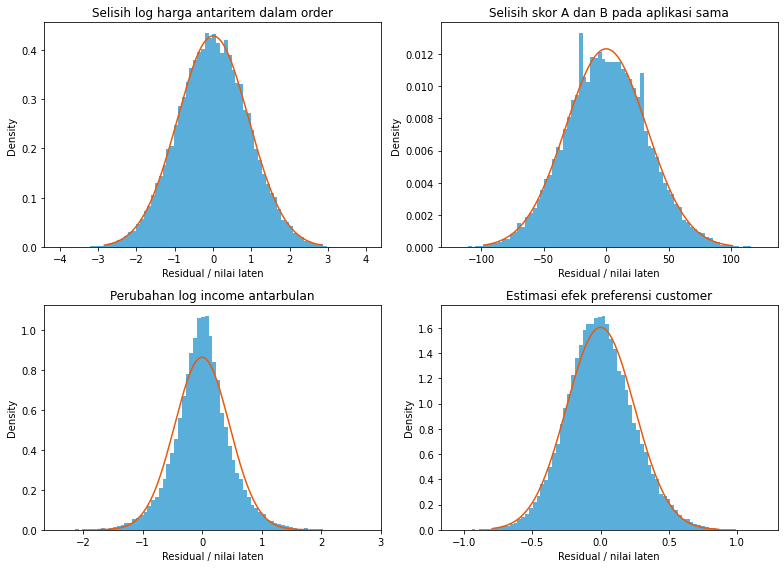

In [19]:
if RECOMPUTE_LATENT_AUDIT:
    fig, axes = plt.subplots(2, 2, figsize=(11, 8))
    panels = [
        (price_samples["item_pair_difference"], "Selisih log harga antaritem dalam order"),
        (bureau_difference, "Selisih skor A dan B pada aplikasi sama"),
        (income_difference, "Perubahan log income antarbulan"),
        (price_samples["latent_price"], "Estimasi efek preferensi customer"),
    ]
    for ax, (values, title) in zip(axes.flat, panels):
        values = np.asarray(values)
        values = values[np.isfinite(values)]
        ax.hist(values, bins=80, density=True, color="#0284c7", alpha=0.65)
        mean, sd = stats.norm.fit(values)
        grid = np.linspace(np.quantile(values, 0.001), np.quantile(values, 0.999), 250)
        ax.plot(grid, stats.norm.pdf(grid, mean, sd), color="#ea580c")
        ax.set(title=title, xlabel="Residual / nilai laten", ylabel="Density")
    plt.tight_layout()
    plt.show()

## 9. Generator pendekatan dan demo denoising

Kode ini menggambarkan beberapa pola yang ditemukan. **Seed demo adalah pilihan kita**.
Probabilitas kategori dan ukuran basket dalam simulasi harga sengaja sederhana; prototype
tidak mereproduksi seluruh populasi, urutan RNG, atau label test. Known latent tersedia
hanya dalam simulasi sehingga RMSE denoising bisa diukur; hasil itu bukan KS kompetisi.

In [20]:
def simulate_workflow(audit, n=10000, demo_seed=91403):
    rng = np.random.Generator(np.random.PCG64(demo_seed))
    mixture = audit["basic_rules"]["workflow_lag_mixture"]
    route = rng.choice(3, size=n, p=mixture["candidate_weights"])
    bounds = mixture["components"]
    low = np.array([r["low_hours"] for r in bounds])[route]
    high = np.array([r["high_hours"] for r in bounds])[route]
    # Formatting application timestamps to seconds explains ceil on observed lags.
    raw_hours = rng.uniform(low, high)
    return pd.DataFrame(
        {
            "route": route,
            "unrounded_delay_hours": raw_hours,
            "observed_delay_seconds": np.ceil(raw_hours * 3600).astype(int),
        }
    )

In [21]:
def simulate_price_measurements(
    audit, n_customers=2000, orders_per_customer=12, demo_seed=73103
):
    rng = np.random.Generator(np.random.PCG64(demo_seed))
    params = audit["ecommerce"]
    categories = list(params["category_log_intercepts"])
    category_intercept = np.array([params["category_log_intercepts"][c] for c in categories])
    # This is a deliberately simple price-only model; order/category probabilities are approximate.
    latent = rng.normal(0, params["estimated_customer_effect_prior_sd"], size=n_customers)
    customer = np.repeat(np.arange(n_customers), orders_per_customer)
    order = np.arange(len(customer))
    order_effect = rng.normal(
        0, params["estimated_shared_order_log_noise_sd"], size=len(order)
    )
    items = rng.choice([1, 2, 3], size=len(order), p=[0.65, 0.24, 0.11])
    item_order = np.repeat(order, items)
    item_customer = customer[item_order]
    category = rng.integers(0, len(categories), size=len(item_order))
    quantity = rng.choice([1, 2, 3, 4], size=len(item_order), p=[0.735, 0.189, 0.057, 0.019])
    noise = rng.normal(0, params["estimated_item_log_noise_sd"], size=len(item_order))
    pre_round_unit = np.exp(
        category_intercept[category] + latent[item_customer] + order_effect[item_order] + noise
    )
    unit = np.maximum(5000, np.rint(pre_round_unit / 1000) * 1000).astype(int)
    result = pd.DataFrame(
        {
            "synthetic_customer_index": item_customer,
            "synthetic_order_index": item_order,
            "product_category": np.array(categories)[category],
            "quantity": quantity,
            "pre_round_unit_price": pre_round_unit,
            "unit_price": unit,
            "item_total": unit * quantity,
            "known_demo_latent": latent[item_customer],
        }
    )
    result["order_total"] = result.groupby("synthetic_order_index").item_total.transform("sum")
    return result

In [22]:
demo_workflow = simulate_workflow(audit, n=10000, demo_seed=91403)
demo_price = simulate_price_measurements(
    audit, n_customers=2000, orders_per_customer=12, demo_seed=73103
)
assert demo_price.item_total.mod(demo_price.quantity * 1000).eq(0).all()
assert demo_price.unit_price.ge(5000).all()
demo_price["adjusted_log_price"] = np.log(
    demo_price.unit_price
) - demo_price.product_category.map(audit["ecommerce"]["category_log_intercepts"])
observed = demo_price.groupby("synthetic_customer_index").adjusted_log_price.mean()
truth = demo_price.groupby("synthetic_customer_index").known_demo_latent.first()
counts = demo_price.groupby("synthetic_customer_index").size()
prior_var = audit["ecommerce"]["estimated_customer_effect_prior_sd"] ** 2
noise_var = audit["ecommerce"]["estimated_item_log_noise_sd"] ** 2
posterior = observed * prior_var / (prior_var + noise_var / counts)
display(
    pd.Series(
        {
            "RMSE_rata_rata_item_demo": np.sqrt(np.mean((observed - truth) ** 2)),
            "RMSE_posterior_sederhana_demo": np.sqrt(np.mean((posterior - truth) ** 2)),
        }
    )
)
display(demo_workflow.groupby("route").observed_delay_seconds.agg(["size", "min", "max"]))
display(demo_price.head())

RMSE_rata_rata_item_demo         0.160327
RMSE_posterior_sederhana_demo    0.132336
dtype: float64

,size,min,max
route,,,
0,4490,721,10800
1,3492,21602,107963
2,2018,129650,431956


,synthetic_customer_index,synthetic_order_index,product_category,quantity,pre_round_unit_price,unit_price,item_total,known_demo_latent,order_total,adjusted_log_price
0,0,0,home,2,999396.164906,999000,1998000,0.096257,1998000,1.224374
1,0,1,fashion,3,99767.387515,100000,300000,0.096257,524000,-0.516201
2,0,1,health,2,111949.505417,112000,224000,0.096257,524000,-0.027022
3,0,2,personal_care,1,52620.405756,53000,53000,0.096257,53000,-0.322630
4,0,3,education,2,180406.279732,180000,360000,0.096257,360000,0.595624


## 10. Uji apakah pola laten membantu KS

CatBoost 500 pohon dan spline dilatih pada tiga fold yang sama dengan versi 5.
Imputasi/encoder model hanya dilatih pada ti. Parameter laten memakai sejarah tanpa label
target. Bobot 25%/50%/100% diperiksa; hasil screening memakai label yang juga dilaporkan,
sehingga mengandung optimisme seleksi. Angka tiga fold tidak dibandingkan langsung dengan
KS sepuluh fold. Tidak ada file submission yang diganti.

Pada clone baru, jalankan notebook 06 dan skrip pembentuk fitur reverse sebelum mengaktifkan
validasi model ini. Audit/simulasi di bagian sebelumnya dapat berjalan tanpa prasyarat model.

In [23]:
def ks(y, probability):
    fpr, tpr, _ = roc_curve(y, probability, drop_intermediate=False)
    return float(np.max(np.abs(tpr - fpr)))


def metrics(y, probability):
    return {
        "ks": ks(y, probability),
        "roc_auc": roc_auc_score(y, probability),
        "average_precision": average_precision_score(y, probability),
        "log_loss": log_loss(y, probability),
    }


def prepare(frame, columns, categorical):
    x = frame[columns].copy()
    for c in categorical:
        x[c] = x[c].fillna("MISSING").astype(str)
    for c in x.columns.difference(categorical):
        x[c] = np.sign(x[c]) * np.log1p(np.abs(x[c]))
    return x


INTERACTION_FEATURES = [
    "installment_income_ratio",
    "v2_existing_total_burden_declared",
    "v3_repay_all_late_1_posterior_24",
    "v4_price_all_equal_order_mean",
    "v2_bureau_history_score_mean",
    "v2_ecom_30d_orders",
]


def fit_spline_plus(spec, data, indices):
    columns = spec["columns"]
    assert set(columns).issubset(data.columns), "A requested feature is absent."
    categorical = data[columns].select_dtypes(include="object").columns.tolist()
    numeric = [c for c in columns if c not in categorical]
    training = data.iloc[indices]
    continuous = [c for c in numeric if training[c].nunique(dropna=True) > 10]
    linear = [c for c in numeric if c not in continuous]
    params = spec["params"]
    transforms = [
        (
            "spline",
            Pipeline(
                [
                    ("fill", SimpleImputer(strategy="median")),
                    (
                        "basis",
                        SplineTransformer(
                            n_knots=params["n_knots"],
                            degree=3,
                            knots="quantile",
                            extrapolation="constant",
                        ),
                    ),
                    ("scale", StandardScaler()),
                ]
            ),
            continuous,
        ),
        (
            "linear",
            Pipeline(
                [
                    ("fill", SimpleImputer(strategy="median")),
                    ("scale", StandardScaler()),
                ]
            ),
            linear,
        ),
        (
            "missing",
            MissingIndicator(features="all", sparse=False, error_on_new=False),
            numeric,
        ),
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore", sparse_output=False),
            categorical,
        ),
    ]
    if params["interactions"]:
        transforms.append(
            (
                "interactions",
                Pipeline(
                    [
                        ("fill", SimpleImputer(strategy="median")),
                        ("scale", StandardScaler()),
                        (
                            "products",
                            PolynomialFeatures(
                                degree=2, interaction_only=True, include_bias=False
                            ),
                        ),
                    ]
                ),
                INTERACTION_FEATURES,
            )
        )
    encoder = ColumnTransformer(transforms)
    weight = params["positive_weight"]
    y = training.target.astype(int)
    with threadpool_limits(limits=4):
        x = encoder.fit_transform(prepare(training, columns, categorical))
        model = LogisticRegression(
            C=params["C"], solver="newton-cholesky", max_iter=80, tol=1e-5
        )
        model.fit(x, y, sample_weight=np.where(y.eq(1), weight, 1))
    return {
        "family": "spline_plus",
        "model": model,
        "encoder": encoder,
        "columns": columns,
        "categorical": categorical,
        "weight": weight,
    }

In [24]:
def fit_reverse_model(spec, data, ti):
    if spec["family"] == "spline_plus":
        return fit_spline_plus(spec, data, ti)
    columns = spec["columns"]
    x = data[columns].copy()
    categorical = x.select_dtypes(include="object").columns.tolist()
    for c in categorical:
        x[c] = x[c].fillna("MISSING").astype(str)
    model = CatBoostClassifier(
        iterations=500,
        learning_rate=0.04,
        loss_function="Logloss",
        eval_metric="AUC",
        random_seed=2026,
        thread_count=8,
        verbose=False,
        allow_writing_files=False,
        **spec["params"]
    )
    model.fit(x.iloc[ti], data.target.iloc[ti].astype(int), cat_features=categorical)
    return {
        "family": "cat",
        "model": model,
        "columns": columns,
        "categorical": categorical,
        "weight": 6,
    }


def predict_reverse_model(bundle, data):
    if bundle["family"] == "cat":
        x = data[bundle["columns"]].copy()
        for c in bundle["categorical"]:
            x[c] = x[c].fillna("MISSING").astype(str)
        p = bundle["model"].predict_proba(x)[:, 1]
    else:
        x = prepare(data, bundle["columns"], bundle["categorical"])
        with threadpool_limits(limits=4):
            p = bundle["model"].predict_proba(bundle["encoder"].transform(x))[:, 1]
    weight = bundle.get("weight", 1)
    return p / (weight * (1 - p) + p)

In [25]:
feature_file = ROOT / "data/processed/application_features_reverse.parquet"
source_oof = ROOT / "artifacts/optimization/v5/selection_oof_tabm.parquet"
validation_report = json.loads(
    (ROOT / "artifacts/reverse_engineering/validation_comparison.json").read_text()
)
if RECOMPUTE_MODEL_VALIDATION and feature_file.exists() and source_oof.exists():
    frame = pd.read_parquet(feature_file)
    data = frame[frame.split.eq("train")].reset_index(drop=True)
    previous = pd.read_parquet(source_oof)
    assert previous.application_id.equals(data.application_id)
    assert previous.target.astype(int).equals(data.target.astype(int))
    oof = previous[["application_id", "target"]].copy()
    oof["version5"] = 0.75 * previous.version4 + 0.25 * previous.v5_tabm_weight1
    specs = json.loads(
        (ROOT / "artifacts/reverse_engineering/validation_definitions.json").read_text()
    )
    folds = list(StratifiedKFold(3, shuffle=True, random_state=8247).split(data, data.target))
    for spec in specs:
        assert not set(spec["columns"]) & EXCLUDED
        oof[spec["name"]] = np.nan
        for fold, (ti, vi) in enumerate(folds, 1):
            filename = f'fold{fold}_{spec["name"]}.joblib'
            local = OUT / "models" / filename
            local.parent.mkdir(exist_ok=True)
            historical = ROOT / "artifacts/reverse_engineering/models" / filename
            cache = local if local.exists() else historical
            if cache.exists() and not FORCE_RETRAIN_REVERSE_MODELS:
                bundle = joblib.load(cache)
                assert bundle["columns"] == spec["columns"]
                actual = bundle["model"].get_params()
                if spec["family"] == "cat":
                    assert all(actual.get(k) == v for k, v in spec["params"].items())
                    assert actual["iterations"] == 500 and actual["random_seed"] == 2026
                else:
                    assert actual["C"] == spec["params"]["C"]
            else:
                bundle = fit_reverse_model(spec, data, ti)
                joblib.dump(bundle, local, compress=3)
            oof.loc[vi, spec["name"]] = predict_reverse_model(bundle, data.iloc[vi])
            print(spec["name"], "fold", fold, "selesai")
    historical = ROOT / "artifacts/reverse_engineering/validation_oof.parquet"
    if historical.exists() and not FORCE_RETRAIN_REVERSE_MODELS:
        expected = pd.read_parquet(historical)
        pd.testing.assert_frame_equal(oof, expected, check_exact=True)
        print("Seluruh prediksi OOF identik dengan eksperimen.")
    comparison = []
    for name in oof.columns[2:]:
        for w in [0] if name == "version5" else [0.25, 0.5, 1]:
            p = oof.version5 if name == "version5" else (1 - w) * oof.version5 + w * oof[name]
            values = [ks(oof.target.iloc[vi], p.iloc[vi]) for _, vi in folds]
            comparison.append(
                {
                    "name": name,
                    "new_model_weight": w,
                    **metrics(oof.target, p),
                    "fold_ks": values,
                    "mean_fold_ks": float(np.mean(values)),
                }
            )
    validation_report["comparison"] = comparison
    (OUT / "validation_comparison.json").write_text(json.dumps(validation_report, indent=2))
else:
    print(
        "Menampilkan validasi historis. Untuk menghitung ulang, siapkan fitur/OOF versi 5 dan fitur reverse."
    )
display(
    pd.DataFrame(validation_report["comparison"])[
        ["name", "new_model_weight", "ks", "mean_fold_ks", "roc_auc"]
    ]
)

reverse_cat5 fold 1 selesai


reverse_cat5 fold 2 selesai


reverse_cat5 fold 3 selesai


reverse_spline fold 1 selesai


reverse_spline fold 2 selesai


reverse_spline fold 3 selesai


Seluruh prediksi OOF identik dengan eksperimen.


,name,new_model_weight,ks,mean_fold_ks,roc_auc
0,version5,0.00,0.525285,0.527524,0.845176
1,reverse_cat5,0.25,0.524847,0.526337,0.845166
2,reverse_cat5,0.50,0.523806,0.525688,0.844828
3,reverse_cat5,1.00,0.520312,0.521919,0.843117
4,reverse_spline,0.25,0.525505,0.527003,0.845229
5,reverse_spline,0.50,0.524651,0.525474,0.844554
6,reverse_spline,1.00,0.517505,0.519495,0.841036


## 11. Kesimpulan dan batas yang harus diperiksa

Beberapa aturan observasi berhasil direkonstruksi: ceil anuitas, grid harga sebelum quantity,
carry saldo, dan support campuran uniform delay. Skala jitter harga/biro dapat diestimasi dari
pengukuran berulang. **Seed dan bitstream generator asli belum berhasil dipulihkan.**

Fitur laten belum meningkatkan KS secara konsisten pada percobaan ini. Kenaikan KS gabungan
spline sangat kecil dan rata-rata fold turun; submission sebelumnya tetap digunakan.
Mean customer nol, Gaussian error, provider independence dan iid income adalah asumsi,
bukan fakta tentang kode generator. Model mendekati distribusi data tidak sama dengan
menemukan program RNG asli atau mengetahui label test.